# Weighting intensity members by landfall

Run with `--land fine --intensity refit-basin`, CHAZ brings storms to the US Atlantic and Gulf
coasts about as often as observed, but too few of them come ashore at hurricane strength: 0.64 of
the observed hurricane landfalls, scaled to the observed North Atlantic storm count, or 0.67
without the scaling, counted by the first-crossing rule of Emanuel (2025)
([intensity.ipynb](intensity.ipynb), section 4, and the first cell below).
This notebook tests a correction applied after that run. Each intensity member gets a weight that moves first landfalls by zone and wind class toward
the observed rates. The weights are fit on one half of 1981–2019 and checked on the other. [intensity.ipynb](intensity.ipynb)
describes the run, its 10 track realizations a year with 40 intensity members each, and
`ocr.risks.hurricane.validate`.

`ocr.risks.hurricane.reweight` finds each member's first landfall: the first hour in which its track
enters land from sea, on the 1/12° country raster that `validate` uses, with the member's wind
interpolated to that hour at 34 kt or more. The landfall
has:

- a zone: the country if it is in `validate.COUNTRIES`, with the US split into TX–AL, FL,
  GA–Carolinas, VA–ME and the Pacific coast, and 'other land' for every other country
- a basin, from the landfall point
- a class, set by that wind: 34–64, 64–96 or ≥96 kt

Each (zone, class) cell gets the weight (n_obs + k) / (chaz_expected + k). n_obs is the number of
observed first landfalls in the fit years, chaz_expected is CHAZ's number divided by its 400
members a year, and k = 2 keeps the weight of a cell with few events near 1. We chose k before
looking at any results. Members with no landfall at 34 kt weigh 1, and a member's weight applies to
everything it counts toward in `validate`. We test three zonings: country, country with other land
split by basin, and basin.

`reweight task` writes each member's first landfall and, for each (zone, basin, class) group, the
`validate` counts summed over its members. Any set of weights then gives a weighted `validate`
table without another pass over the tracks. Unweighted, the group sums reproduce the `validate`
tables exactly:


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ocr.risks.hurricane import reweight, store, validate

RUN = 'TCGI_CRH_PI-land-fine-intensity-refit-basin'
SOURCES = ('ibtracs', RUN)
HALVES = {'1981-1999': range(1981, 2000), '2000-2019': range(2000, 2020)}
SPLITS = {
    'fit 1981-1999, test 2000-2019': ('1981-1999', '2000-2019'),
    'fit 2000-2019, test 1981-1999': ('2000-2019', '1981-1999'),
}
LABEL = {
    'zone': 'country',
    'zone, other land by basin': 'country, other land by basin',
    'basin': 'basin',
}
US = [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)]
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)

annual = {source: validate.load(source) for source in SOURCES}
records = {
    source: pd.read_parquet(store.path(reweight.keys(source)['records'])) for source in SOURCES
}
grouped = {
    source: pd.read_parquet(store.path(reweight.keys(source)['grouped'])) for source in SOURCES
}
members = {source: annual[source]['members'] for source in SOURCES}
obs, chaz = records['ibtracs'], records[RUN]


def weights(fit, scheme, k=reweight.K):
    return reweight.weights(chaz, obs, members[RUN], members['ibtracs'], HALVES[fit], scheme, k)


def tables(fit, k=reweight.K):
    out = {'IBTrACS': annual['ibtracs'], 'unweighted': annual[RUN]}
    for scheme in reweight.SCHEMES:
        out[LABEL[scheme]] = reweight.weighted_annual(
            grouped[RUN], weights(fit, scheme, k), scheme, members[RUN]
        )
    return out


for source in SOURCES:
    summed = reweight.weighted_annual(grouped[source], None, 'zone', members[source])
    cols = annual[source].columns.difference(['members'])
    diff = (summed[cols] - annual[source].loc[summed.index, cols]).abs().to_numpy().max()
    print(f'{source}: unweighted group sums against validate.annual, max |difference| {diff}')

ALL = list(range(1981, 2020))
scaled_rates = validate.metrics({'IBTrACS': annual['ibtracs'], 'CHAZ': annual[RUN]}, ALL).loc[US]
raw = {
    source: annual[source].loc[ALL, US].sum() / annual[source].loc[ALL, 'members'].sum()
    for source in SOURCES
}
print('US Atlantic and Gulf landfalls, CHAZ over IBTrACS, 1981-2019:')
print(
    pd.DataFrame(
        {
            'scaled': scaled_rates['CHAZ'] / scaled_rates['IBTrACS'],
            'not scaled': raw[RUN] / raw['ibtracs'],
        }
    )
    .round(2)
    .to_string()
)

ibtracs: unweighted group sums against validate.annual, max |difference| 0.0
TCGI_CRH_PI-land-fine-intensity-refit-basin: unweighted group sums against validate.annual, max |difference| 0.0
US Atlantic and Gulf landfalls, CHAZ over IBTrACS, 1981-2019:
                             scaled  not scaled
Atl+Gulf landfalls >= 34 kt    0.96        1.00
Atl+Gulf landfalls >= 64 kt    0.64        0.67
Atl+Gulf landfalls >= 96 kt    0.50        0.53


## 1. The weights

The table has the country-zone weights for the US zones, Cuba, Mexico and other land, fit on each
half. CHAZ makes too many weak first landfalls: at 34–64 kt the weight on other land is 0.39 fit
on 1981–1999 and 0.49 fit on 2000–2019, and on Mexico 0.41 and 0.79. Some cells rest on a few
events and change a lot between the halves. TX–AL at 64–96 kt has a weight of 2.34 from 8 observed
landfalls in 1981–1999, and 0.81 from 2 in 2000–2019.


In [2]:
shown = [
    zone
    for zone in weights('1981-1999', 'zone').index.get_level_values('key').unique()
    if zone.startswith('USA') or zone in ('CUB', 'MEX', 'other land')
]
by_half = pd.concat({half: weights(half, 'zone') for half in HALVES}, axis=1)
by_half = by_half[by_half.index.get_level_values('key').isin(shown)]
by_half.style.format('{:.2f}').set_caption(
    f"Country zones, k = {reweight.K:g}: observed first landfalls (n_obs) and CHAZ's at the "
    'observed member-years (chaz_expected) in each half, and the weight'
)

## 2. Held-out test

The weights are fit on one half of 1981–2019 and applied to the other. The tables give US Atlantic
and Gulf landfalls on the test years over observed, and the North Atlantic storm counts behind the
scaling.

On the test years, US hurricane landfalls go from 0.83 to 1.12 of observed with country zones on
2000–2019, and from 0.45 to 0.43 on 1981–1999 (0.43–0.47 across the zonings). Most of the 2000–2019 rise comes from the North
Atlantic scaling. `validate.metrics` scales North Atlantic quantities to the observed North Atlantic
storm count. The weights on weak first landfalls on other land and in Mexico are below 1, so they
cut CHAZ's North Atlantic
tropical storms on 2000–2019 from 15.41 to 12.24 a year, and the scaling factor rises from 1.04 to
1.31. Without the scaling, US hurricane landfalls go from 0.80 to 0.85 of observed on 2000–2019 and
from 0.54 to 0.43 on 1981–1999. Unweighted, the run falls short in both halves, more in
1981–1999.

In [3]:
by_split = {split: tables(fit) for split, (fit, test) in SPLITS.items()}
rows = {}
for split, (fit, test) in SPLITS.items():
    years = list(HALVES[test])
    us_rates = validate.metrics(by_split[split], years).loc[US]
    rows[(split, 'scaled')] = us_rates.drop(columns='IBTrACS').div(us_rates['IBTrACS'], axis=0)
    raw = pd.DataFrame(
        {
            name: table.loc[years, US].sum() / table.loc[years, 'members'].sum()
            for name, table in by_split[split].items()
        }
    )
    rows[(split, 'not scaled')] = raw.drop(columns='IBTrACS').div(raw['IBTrACS'], axis=0)
pd.concat(rows).style.format('{:.2f}').set_caption(
    'US Atlantic and Gulf landfalls on the test years over IBTrACS, with and without the '
    'scaling to the observed North Atlantic storm count'
)

In [4]:
rows = {}
for split, (fit, test) in SPLITS.items():
    years = list(HALVES[test])
    na = pd.Series(
        {
            name: table.loc[years, 'NA TS'].sum() / table.loc[years, 'members'].sum()
            for name, table in by_split[split].items()
        }
    )
    rows[split] = pd.DataFrame(
        {'NA tropical storms per yr': na, 'scaling factor': na['IBTrACS'] / na}
    )
pd.concat(rows).style.format('{:.2f}').set_caption(
    'North Atlantic storms reaching 34 kt on the test years, per member-year, and the factor '
    'validate.metrics multiplies North Atlantic quantities by'
)

## 3. First landfalls and sample size

About half of US hurricane landfalls come from storms whose first landfall was outside the US. Over 1981–2019, 0.528 of observed US
Atlantic and Gulf hurricane landfalls, and 0.505 of CHAZ's, come from storms (for CHAZ, members)
whose first landfall is in a US zone. Almost all the rest first came ashore on other land (0.283
and 0.320), in Cuba (0.113 and 0.103) or in Mexico (0.075 and 0.069), and take those zones'
weights. Other land's weights are all below 1, so they pull these landfalls down.

In [5]:
shares = {}
for source, label in (('ibtracs', 'IBTrACS'), (RUN, 'CHAZ')):
    by_zone = grouped[source].groupby('zone')['Atl+Gulf landfalls >= 64 kt'].sum()
    shares[label] = by_zone / by_zone.sum()
shares = pd.DataFrame(shares).rename(index={reweight.NONE: '(none at 34 kt or more)'})
shares = shares[shares.max(axis=1) > 0.005].sort_values('IBTrACS', ascending=False)
shares.loc['all US zones'] = shares[shares.index.str.startswith('USA')].sum()
shares.style.format('{:.3f}').set_caption(
    'Share of US Atlantic and Gulf hurricane landfalls (64 kt), 1981-2019, by the zone of the '
    "member's first landfall"
)

,IBTrACS,CHAZ
zone,,
other land,0.283,0.320
USA TX-AL,0.245,0.155
USA GA-Car,0.151,0.124
CUB,0.113,0.103
USA FL,0.094,0.171
MEX,0.075,0.069
USA VA-ME,0.038,0.056
all US zones,0.528,0.505


Observed events are also few. The halves have 27 and 26 observed US hurricane landfalls, 3 and 7
of them major, spread over four Atlantic and Gulf zones and two classes.

In [6]:
observed = annual['ibtracs']
pd.DataFrame(
    {half: observed.loc[list(years), US].sum() for half, years in HALVES.items()}
).style.format('{:.0f}').set_caption('Observed US Atlantic and Gulf landfalls in each half')

,1981-1999,2000-2019
Atl+Gulf landfalls >= 34 kt,51,69
Atl+Gulf landfalls >= 64 kt,27,26
Atl+Gulf landfalls >= 96 kt,3,7


## 4. Storm counts in each half

Worldwide, CHAZ makes 84.81 storms reaching 34 kt per member-year in 1981–1999 and 103.89 in 2000–2019. IBTrACS has 88.58
and 88.60. In the North Atlantic both rise, CHAZ from 12.66 to 15.41 and IBTrACS from 10.58 to
16.05. Year by year, CHAZ's global count steps up around 1998–2000 and stays high, and IBTrACS has
no such step.

In [7]:
rows = {}
for source, label in (('ibtracs', 'IBTrACS'), (RUN, 'CHAZ')):
    table = annual[source]
    for half, years in HALVES.items():
        years = list(years)
        member_years = table.loc[years, 'members'].sum()
        rows[(label, half)] = {
            'global': table.loc[years, 'TS formed global'].sum() / member_years,
            'North Atlantic': table.loc[years, 'NA TS'].sum() / member_years,
        }
pd.DataFrame(rows).T.style.format('{:.2f}').set_caption(
    'Storms reaching 34 kt per year (CHAZ: per member-year)'
)

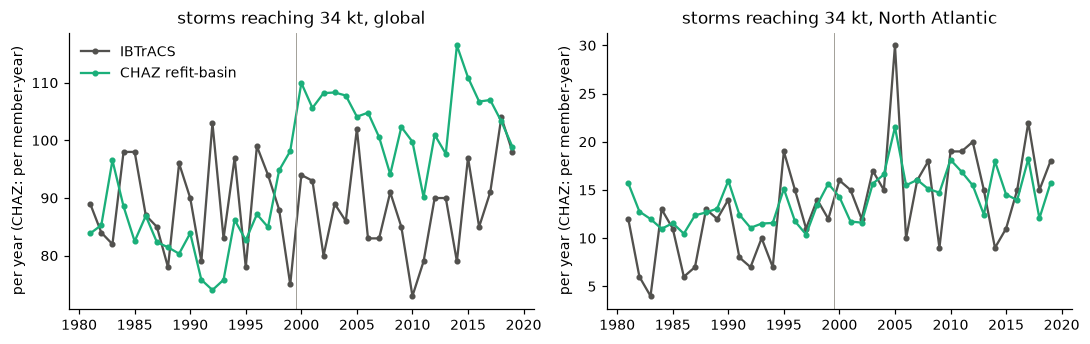

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in zip(axes, ('TS formed global', 'NA TS'), ('global', 'North Atlantic')):
    for source, label, color in (
        ('ibtracs', 'IBTrACS', '#52514e'),
        (RUN, 'CHAZ refit-basin', '#1baf7a'),
    ):
        table = annual[source]
        ax.plot(
            table.index,
            table[col] / table['members'],
            color=color,
            lw=1.5,
            marker='o',
            ms=3,
            label=label,
        )
    ax.axvline(1999.5, color='#9c9a92', lw=0.6)
    ax.set(title=f'storms reaching 34 kt, {title}', ylabel='per year (CHAZ: per member-year)')
axes[0].legend(frameon=False)
fig.tight_layout()

A weight fit on one half corrects that half's count error along with its intensity error, and
applies the same correction to the other half, whose count error is different. The different
storm counts of the halves can also move any test that fits on one half of 1981–2019 and scores on
the other, including the test in [intensity.ipynb](intensity.ipynb), section 5, that fits
the refits on 1981–1999 only, though those fits learn 12-hour wind changes and do not correct
storm counts. CHAZ seeds storms in proportion to global
TCGI ([genesis-index.ipynb](genesis-index.ipynb), section 4), and genesis-index.ipynb, section 5,
traces the step to TCGI and its PI.

## Summary

Weighting members by the zone and class of their first landfall, fit on one half of 1981–2019, does
not consistently improve US hurricane landfalls on the other half. None of the runs in the notebooks uses it. A correction for the US would need to key on every US
landfall rather than only the first. With 26 or 27 observed US hurricane landfalls in each half, we would fit
at most one factor for the whole coast rather than one per zone. Without the North Atlantic
scaling, the unweighted run makes 0.80 of the observed US hurricane landfalls on 2000–2019 and
0.54 on 1981–1999, and the halves also differ in CHAZ's storm count (section 4). One factor fit on
all of 1981–2019 would leave 2000–2019 above the observed rate and 1981–1999 below it.

Open:

- **CHAZ's storm count over 1981–2019.** The step between the halves follows ERA5's TCGI and its
  PI ([genesis-index.ipynb](genesis-index.ipynb), section 5); how much it moves the held-out tests
  here and in [intensity.ipynb](intensity.ipynb) is open.
- **US landfall intensity.** Either one factor for the US coast at hurricane strength, fit on all of
  1981–2019, or no correction, with the final maps compared against Meiler et al.'s. The storm
  count comes first, since, like the landfall rate, it differs between the halves.